In [22]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ========================================
# 設定
# ========================================
IMAGE_SIZE = 9
N_CLASS = 3
DATA_DIR = Path("./TrainImage")

N_FILTER = 4
FILTER_SIZE = 3

LEARNING_RATE = 0.05
EPOCHS = 10

np.random.seed(0)

In [23]:
# ========================================
# PNG画像の読み込み
# ========================================

X = []
T = []

for class_id in range(N_CLASS):
    class_dir = DATA_DIR / f"class_{class_id}"
    image_files = sorted(class_dir.glob("*.png"))
    for image_file in image_files:
        img = plt.imread(image_file)
        # RGBまたはRGBAの場合は最初のチャンネルを使用
        if img.ndim == 3:
            img = img[:, :, 0]
        # 画素値を0～1に正規化
        if img.max() > 1.0:
            img = img / 255.0
        # 画像サイズの確認
        if img.shape != (IMAGE_SIZE, IMAGE_SIZE):
            raise ValueError(
                f"画像サイズが不正です: {image_file} "
                f"実際のサイズ={img.shape}, "
                f"期待するサイズ={(IMAGE_SIZE, IMAGE_SIZE)}"
            )
        X.append(img)
        T.append(class_id)

X = np.array(X, dtype=float)
T = np.array(T, dtype=int)

T_onehot = np.eye(N_CLASS)[T]

# クラスごとの画像枚数
class_counts = np.bincount(T, minlength=N_CLASS)

print("Loaded images:", len(X))
print("Image shape:", X.shape)
print("Class counts:", class_counts)

Loaded images: 300
Image shape: (300, 9, 9)
Class counts: [100 100 100]


In [24]:
# ========================================
# ネットワークの設定
# ========================================

# 畳み込み層の出力サイズ
FEATURE_SIZE = IMAGE_SIZE - FILTER_SIZE + 1

# 全結合層の入力数
N_FLAT = N_FILTER * FEATURE_SIZE * FEATURE_SIZE

# 畳み込みフィルタの重み
K = np.random.randn(N_FILTER, FILTER_SIZE, FILTER_SIZE) * 0.1

b_conv = np.zeros(N_FILTER)

# 全結合層の重み
W = np.random.randn(N_FLAT, N_CLASS) * 0.1

b = np.zeros(N_CLASS)

print()
print("Input size:", IMAGE_SIZE, "x", IMAGE_SIZE)
print("Filter size:", FILTER_SIZE, "x", FILTER_SIZE)
print("Feature size:", FEATURE_SIZE, "x", FEATURE_SIZE)
print("Number of filters:", N_FILTER)
print("Fully connected input:", N_FLAT)


Input size: 9 x 9
Filter size: 3 x 3
Feature size: 7 x 7
Number of filters: 4
Fully connected input: 196


In [25]:
# ========================================
# 活性化関数の定義
# ========================================
def sigmoid(x):# Sigmoid関数（入力値を-50～50に制限し、指数関数のオーバーフローを防止）
    return 1.0 / (1.0 + np.exp(-np.clip(x, -50, 50)))

def softmax(x):# Softmax関数（各出力値を0～1の確率に変換し、合計を1に正規化）
    x = x - np.max(x)
    y = np.exp(x)
    return y / np.sum(y)

# ========================================
# 畳み込み処理　（入力画像にフィルタを適用し、特徴マップを生成）
# ========================================
def convolution(x, K, b_conv):
    C = np.zeros((N_FILTER, FEATURE_SIZE, FEATURE_SIZE))
    for f in range(N_FILTER):
        for i in range(FEATURE_SIZE):
            for j in range(FEATURE_SIZE):
                patch = x[i:i+FILTER_SIZE, j:j+FILTER_SIZE]  # 入力画像からフィルタと同じサイズの領域を抽出
                z = np.sum(patch * K[f]) + b_conv[f]  # フィルタとの要素積の総和にバイアスを加算
                C[f, i, j] = sigmoid(z)  # Sigmoid関数を適用して特徴マップに格納
    return C

# ========================================
# 順伝播
# ========================================
def forward(x, K, b_conv, W, b):
    C = convolution(x, K, b_conv)
    flat = C.reshape(-1)
    z = np.dot(flat, W) + b
    y = softmax(z)
    return C, flat, y

In [26]:
# ========================================
# 学習
# ========================================
def train(X, T_onehot, K, b_conv, W, b, epochs, learning_rate):
    error_history = []
    accuracy_history = []

    for epoch in range(epochs):
        indices = np.random.permutation(len(X))
        total_error = 0
        correct = 0

        for n in indices:
            x = X[n]
            t = T_onehot[n]
            # ----------------------------
            # 順伝播
            # ----------------------------
            C, flat, y = forward(x, K, b_conv, W, b)

            # 二乗誤差
            error = 0.5 * np.sum((y - t) ** 2)
            total_error += error

            if np.argmax(y) == np.argmax(t):
                correct += 1

            # ----------------------------
            # 出力層の誤差
            # Softmax + 二乗誤差
            # ----------------------------
            delta_y = y - t
            delta_out = y * (delta_y - np.sum(y * delta_y))

            # ----------------------------
            # 全結合層の勾配
            # ----------------------------
            dW = np.outer(flat, delta_out)
            db = delta_out

            # ----------------------------
            # 畳み込み層への誤差逆伝播
            # ----------------------------
            delta_flat = np.dot(W, delta_out)
            delta_C = delta_flat.reshape(N_FILTER, FEATURE_SIZE, FEATURE_SIZE)
            delta_C = delta_C * C * (1.0 - C)

            dK = np.zeros_like(K)
            db_conv = np.zeros_like(b_conv)

            for f in range(N_FILTER):
                for i in range(FEATURE_SIZE):
                    for j in range(FEATURE_SIZE):
                        patch = x[i:i+FILTER_SIZE, j:j+FILTER_SIZE]
                        dK[f] += delta_C[f, i, j] * patch
                        db_conv[f] += delta_C[f, i, j]

            # ----------------------------
            # 重みの更新
            # ----------------------------
            W -= learning_rate * dW
            b -= learning_rate * db
            K -= learning_rate * dK
            b_conv -= learning_rate * db_conv

        error_history.append(total_error / len(X))
        accuracy_history.append(correct / len(X))

        if (epoch + 1) % 2 == 0:
            print("Epoch:", epoch + 1, "Error:", error_history[-1], "Accuracy:", accuracy_history[-1])

    return K, b_conv, W, b, error_history, accuracy_history

In [27]:
# ========================================
# 分類
# ========================================
def predict(X, K, b_conv, W, b):
    predictions = []
    for x in X:
        C, flat, y = forward(x, K, b_conv, W, b)
        predictions.append(np.argmax(y))
    return np.array(predictions)

In [28]:
# ========================================
# 学習前の正解率
# ========================================
pred_before = predict(X, K, b_conv, W, b)
accuracy_before = np.mean(pred_before == T)

# ========================================
# 学習の実行
# ========================================
K, b_conv, W, b, error_history, accuracy_history = train(X, T_onehot, K, b_conv, W, b, EPOCHS, LEARNING_RATE)

# ========================================
# 学習後の評価
# ========================================
pred_after = predict(X, K, b_conv, W, b)
accuracy_after = np.mean(pred_after == T)

print()
print("Accuracy before learning:", accuracy_before)
print("Accuracy after learning:", accuracy_after)

Epoch: 2 Error: 0.254603232050098 Accuracy: 0.6
Epoch: 4 Error: 0.07147568310833023 Accuracy: 0.9433333333333334
Epoch: 6 Error: 0.03728626663682828 Accuracy: 0.96
Epoch: 8 Error: 0.02863556508746982 Accuracy: 0.9633333333333334
Epoch: 10 Error: 0.021540978992246083 Accuracy: 0.9833333333333333

Accuracy before learning: 0.3333333333333333
Accuracy after learning: 0.9866666666666667


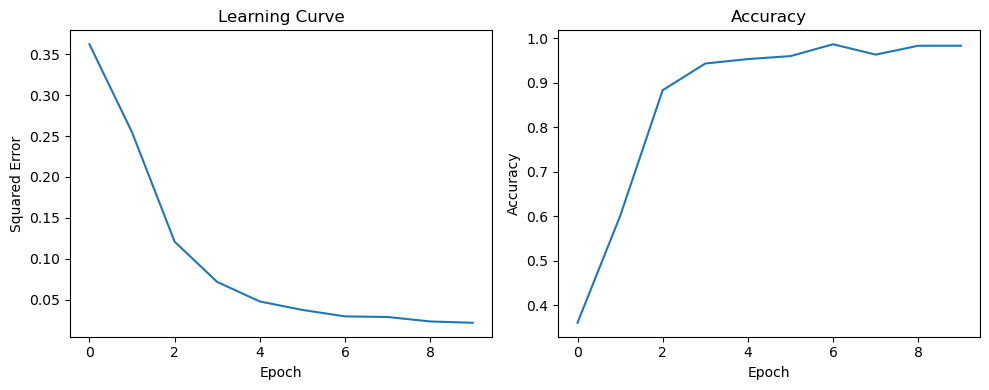

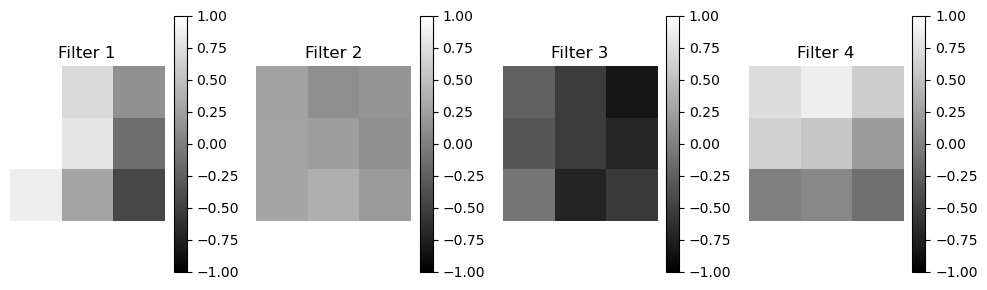

In [29]:
# ========================================
# 学習曲線
# ========================================
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(error_history)
plt.xlabel("Epoch")
plt.ylabel("Squared Error")
plt.title("Learning Curve")

plt.subplot(1, 2, 2)
plt.plot(accuracy_history)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy")

plt.tight_layout()
plt.show()

# ========================================
# 畳み込みフィルタの表示
# ========================================

plt.figure(figsize=(10, 3))
for f in range(N_FILTER):
    plt.subplot(1, N_FILTER, f + 1)
    plt.imshow(K[f], cmap="gray", vmin=-1, vmax=1)
    plt.colorbar()
    plt.title("Filter " + str(f + 1))
    plt.axis("off")

plt.tight_layout()
plt.show()

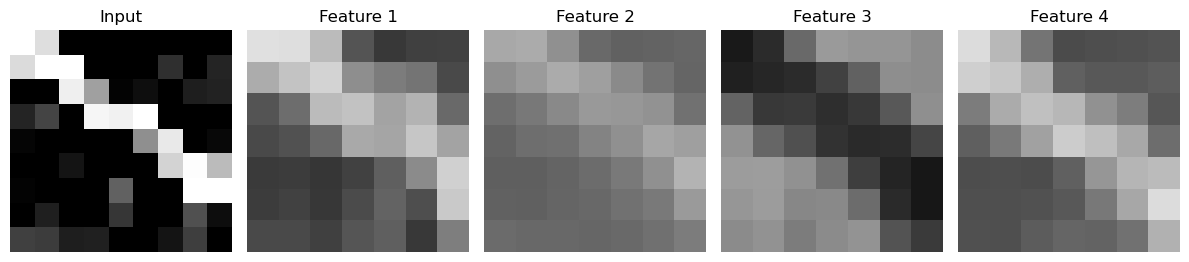

In [30]:
# ========================================
# 入力画像と特徴マップの表示
# ========================================
sample = 100
C, flat, y = forward(X[sample], K, b_conv, W, b)
plt.figure(figsize=(12, 3))
plt.subplot(1, N_FILTER + 1, 1)
plt.imshow(X[sample], cmap="gray")
plt.title("Input")
plt.axis("off")

for f in range(N_FILTER):
    plt.subplot(1, N_FILTER + 1, f + 2)
    plt.imshow(C[f], cmap="gray", vmin=0, vmax=1)
    plt.title("Feature " + str(f + 1))
    plt.axis("off")

plt.tight_layout()
plt.show()

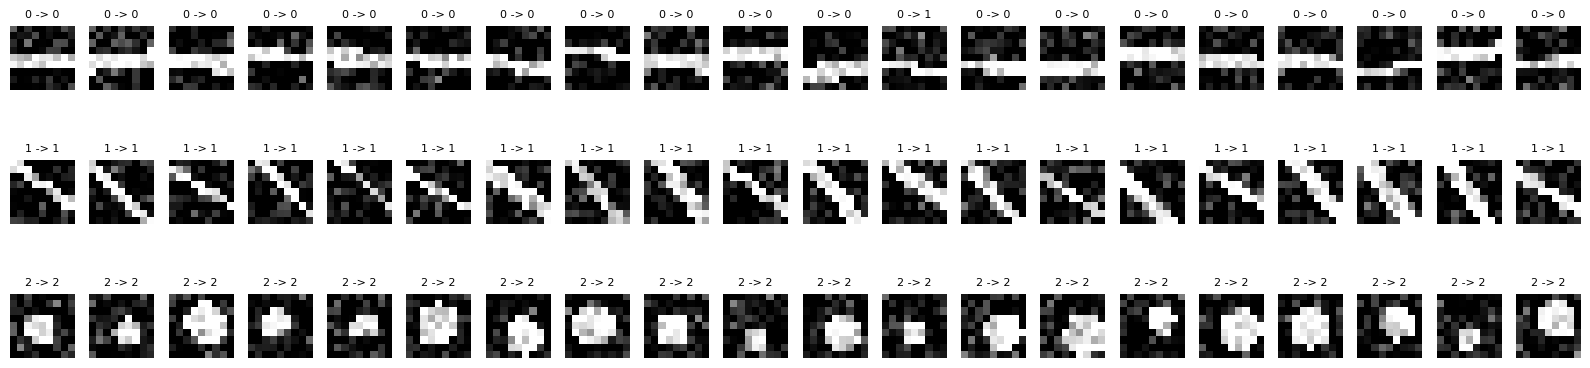

In [31]:
# ========================================
# 入力データと分類結果の表示
# ========================================

MAX_DISPLAY = 20
fig, axes = plt.subplots(N_CLASS, MAX_DISPLAY, figsize=(MAX_DISPLAY * 0.8, N_CLASS * 1.5), squeeze=False)

for class_id in range(N_CLASS):
    indices = np.where(T == class_id)[0]

    for col in range(MAX_DISPLAY):
        ax = axes[class_id, col]

        if col < len(indices):
            n = indices[col]
            ax.imshow(X[n], cmap="gray")
            ax.set_title(str(T[n]) + " -> " + str(pred_after[n]), fontsize=8)

        ax.axis("off")

plt.tight_layout()
plt.show()